# 6. Scoring

The scorer compares one prediction with the hidden truth of one episode and returns
a number between 0 and 1 with an outcome word. It reads no files and uses no
network, so a training loop can call it on each rollout. This notebook runs it on
the loaded episode with several predictions and shows what each rule does.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path("..").resolve()))
sys.path.insert(0, str(Path("../tests").resolve()))
plt.rcParams["figure.figsize"] = (11, 3.5)
plt.rcParams["figure.dpi"] = 110

EPISODES = Path("../data/episodes/s98_v2")


def load_episode(episode_id="ep_0001"):
    """Return (time, flux, truth) for one real episode, or a synthetic one if the set is absent."""
    if EPISODES.exists():
        from stargazer.episodes import EpisodeSet

        episode_set = EpisodeSet(EPISODES)
        time, flux, _ = episode_set.load(episode_id)
        return time, flux, episode_set.truth[episode_id]
    from conftest import synthetic_lc

    from stargazer.inject import inject, make_truth

    time, flux, _ = synthetic_lc(days=57.0)
    time = time - time.min()
    star = {"teff": 5500.0, "logg": 4.45, "radius_rsun": 0.95, "tmag": 10.0, "mass_msun": 0.95}
    truth = make_truth(period=0.7764, t0=0.1453, depth=0.0016, b=0.3, star=star)
    transit = {"period": truth.period, "t0": truth.t0, "duration": truth.duration, "depth": truth.depth}
    record = {"kind": "transit", "n_transits": 73, "snr": 60.0, "transit": transit}
    return time, inject(time, flux, truth), record


time, flux, truth = load_episode()
print(f"{len(time)} points over {time.max() - time.min():.1f} days; truth kind {truth['kind']}")

26521 points over 57.4 days; truth kind transit


## The periodic form

A prediction with a period is credited 1.0 at the true period, 0.5 at half or
double, 0.25 at a third or triple, within 1 percent. The epoch is folded on the true
period and must fall within half a duration of a transit centre; it is worth 30
percent of the credit. A wrong period scores zero, the same as a false alarm.

In [2]:
from stargazer.score import score_episode

transit = truth["transit"]
predictions = {
    "right period and epoch": {"detected": True, "period": transit["period"], "t0": transit["t0"]},
    "right period, wrong epoch": {
        "detected": True,
        "period": transit["period"],
        "t0": transit["t0"] + 0.4 * transit["period"],
    },
    "double period": {"detected": True, "period": 2 * transit["period"], "t0": transit["t0"]},
    "wrong period": {"detected": True, "period": 1.37 * transit["period"], "t0": transit["t0"]},
    "no detection": {"detected": False},
}
for label, prediction in predictions.items():
    row = score_episode(prediction, truth)
    print(f"{label:28s} outcome {row['outcome']:13s} score {row['score']:.2f}")

right period and epoch       outcome hit           score 1.00
right period, wrong epoch    outcome hit           score 0.70
double period                outcome alias         score 0.50
wrong period                 outcome wrong_period  score 0.00
no detection                 outcome miss          score 0.00


## The single-event form

A prediction with no period claims one event at a time. The event passes the same
epoch check. It scores 1.0 on an episode with one transit in the data, where no
period was measurable, and 0.5 where the data held more transits. The loaded
episode has many transits, so an event on one of them scores 0.5.

In [3]:
one_transit = {**truth, "n_transits": 1}
on_transit = {
    "detected": True,
    "t0": transit["t0"],
    "duration": transit["duration"],
    "depth": transit["depth"],
}
off_transit = {**on_transit, "t0": transit["t0"] + 0.5 * transit["period"]}
for label, prediction, record in (
    ("event on a transit, many in the data", on_transit, truth),
    ("event on a transit, one in the data", on_transit, one_transit),
    ("event between transits", off_transit, truth),
):
    row = score_episode(prediction, record)
    print(f"{label:38s} outcome {row['outcome']:13s} score {row['score']:.2f}")

event on a transit, many in the data   outcome event_hit     score 0.50
event on a transit, one in the data    outcome event_hit     score 1.00
event between transits                 outcome wrong_event   score 0.00


## A null episode

On an episode with no injection, "none" scores 1.0 and any detection scores 0.0.

In [4]:
null = {"kind": "null"}
for label, prediction in (("no detection", {"detected": False}), ("a detection", on_transit)):
    row = score_episode(prediction, null)
    print(f"{label:14s} outcome {row['outcome']:12s} score {row['score']:.2f}")

no detection   outcome true_null    score 1.00
a detection    outcome false_alarm  score 0.00


## The score against the period error

The plot sweeps the predicted period across the true one and shows the score. The
tolerance is a strict band of 1 percent; the aliases at half and double are narrower
bands at half credit.

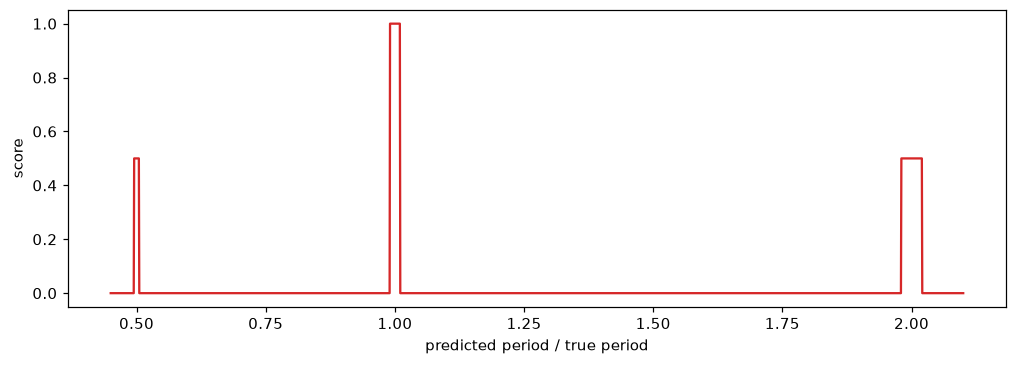

In [5]:
ratios = np.linspace(0.45, 2.1, 2000)
scores = [
    score_episode({"detected": True, "period": ratio * transit["period"], "t0": transit["t0"]}, truth)[
        "score"
    ]
    for ratio in ratios
]
fig, axis = plt.subplots()
axis.plot(ratios, scores, color="tab:red")
axis.set_xlabel("predicted period / true period")
axis.set_ylabel("score")
plt.show()